In [1]:
import os
import shutil
import yaml

# ۱. نصب ultralytics و kaggle
!pip install --upgrade kaggle ultralytics

# ۲. تنظیم توکن Kaggle (نام کاربری خود را وارد کنید)
os.environ["KAGGLE_USERNAME"] = "YOUR_KAGGLE_USERNAME"
os.environ["KAGGLE_KEY"] = "KGAT_da58061e30529fdc1551bbf0b296caff"

print("⏳ در حال دانلود دیتاست پلاک‌یاب از کگل...")
!kaggle datasets download -d paryaparvan/iranian-license-plate

print("📦 استخراج فایل‌ها...")
!mkdir -p /content/dataset_detector
!unzip -q iranian-license-plate.zip -d /content/dataset_detector

if os.path.exists("iranian-license-plate.zip"):
    os.remove("iranian-license-plate.zip")

# ۳. تنظیم و بازنویسی data.yaml برای اطمینان از صحت مسیرها در کولب
detector_yaml_path = "/content/dataset_detector/data.yaml"

detector_yaml_data = {
    "path": "/content/dataset_detector",
    "train": "train/images",
    "val": "valid/images",  # در صورت وجود پوشه valid یا validation
    "test": "test/images",
    "names": {0: "license_plate"},
}

with open(detector_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(detector_yaml_data, f, allow_unicode=True)

print("✨ دیتاسِت آماده است! مسیر فایل تنظیمات:", detector_yaml_path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.4/65.4 kB 7.6 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2
⏳ در حال دانلود دیتاست پلاک‌یاب از کگل...
Dataset URL: https://www.kaggle.com/datasets/paryaparvan/iranian-license-plate
License(s): apache-2.0
100% 153M/153M [00:08<00:00, 17.8MB/s]

📦 استخراج فایل‌ها...
✨ دیتاسِت آماده است! مسیر فایل تنظیمات: /content/dataset_detector/data.yaml


In [2]:
import os
import glob
import yaml

base_path = "/content/dataset_detector"

# بررسی پوشه‌های موجود در دیتاست
all_folders = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
print("پوشه‌های موجود در دیتاست:", all_folders)

# پیدا کردن پوشه‌های images و labels
images_dir = glob.glob(f"{base_path}/**/images", recursive=True)
print("مسیرهای یافت شده برای images:", images_dir)

# تشخیص مسیر train و validation
train_path = "train/images"
val_path = "val/images"

# اگر پوشه valid یا validation وجود داشت، مسیر آن را ست کن
for path in images_dir:
    rel_path = os.path.relpath(path, base_path)
    if "val" in rel_path or "valid" in rel_path:
        val_path = rel_path
        break

# اگر پوشه val وجود نداشت، از همان train برای validation هم استفاده کن
if not os.path.exists(os.path.join(base_path, val_path)):
    print("⚠️ پوشه validation جداگانه یافت نشد؛ از پوشه train استفاده می‌شود.")
    val_path = train_path

# بازنویسی دقیق data.yaml
detector_yaml_path = f"{base_path}/data.yaml"
detector_yaml_data = {
    'path': base_path,
    'train': train_path,
    'val': val_path,
    'names': {0: 'license_plate'}
}

with open(detector_yaml_path, 'w', encoding='utf-8') as f:
    yaml.dump(detector_yaml_data, f, allow_unicode=True)

print("✅ فایل data.yaml با موفقیت اصلاح شد:")
print(yaml.dump(detector_yaml_data))

پوشه‌های موجود در دیتاست: ['ir_license_plate']
مسیرهای یافت شده برای images: ['/content/dataset_detector/ir_license_plate/train/images', '/content/dataset_detector/ir_license_plate/test/images', '/content/dataset_detector/ir_license_plate/valid/images']
✅ فایل data.yaml با موفقیت اصلاح شد:
names:
  0: license_plate
path: /content/dataset_detector
train: train/images
val: ir_license_plate/valid/images



In [ ]:
import yaml
from ultralytics import YOLO

# ۱. اصلاح دقیق مسیرها بر اساس زیرپوشه ir_license_plate
base_path = "/content/dataset_detector"
detector_yaml_path = f"{base_path}/data.yaml"

detector_yaml_data = {
    "path": base_path,
    "train": "ir_license_plate/train/images",
    "val": "ir_license_plate/valid/images",
    "test": "ir_license_plate/test/images",
    "names": {0: "license_plate"},
}

with open(detector_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(detector_yaml_data, f, allow_unicode=True)

print("✅ فایل data.yaml با مسیرهای دقیق اصلاح شد:")
print(yaml.dump(detector_yaml_data))

# ۲. شروع آموزش مدل پلاک‌یاب
print("🚀 شروع آموزش مدل تشخیص پلاک (Stage 1)...")
model_detector = YOLO("yolov8n.pt")

results = model_detector.train(
    data=detector_yaml_path,
    epochs=25,
    imgsz=640,
    batch=16,
    project="stage1_detector",
    name="plate_finder",
)

print("\n✅ آموزش مرحله اول با موفقیت تمام شد!")

✅ فایل data.yaml با مسیرهای دقیق اصلاح شد:
names:
  0: license_plate
path: /content/dataset_detector
test: ir_license_plate/test/images
train: ir_license_plate/train/images
val: ir_license_plate/valid/images

🚀 شروع آموزش مدل تشخیص پلاک (Stage 1)...
Ultralytics 8.4.128 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_detector/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ مدل پلاک‌یاب با موفقیت از گوگل درایو بارگذاری شد.

📸 یک عکس ماشین برای تست پلاک‌یاب آپلود کنید:


Saving 4.jpg to 4.jpg

0: 640x640 4 license_plates, 7.2ms
Speed: 61.4ms preprocess, 7.2ms inference, 35.2ms postprocess per image at shape (1, 3, 640, 640)

--- پلاک کات‌شده شماره 1 ---



--- پلاک کات‌شده شماره 2 ---



--- پلاک کات‌شده شماره 3 ---



--- پلاک کات‌شده شماره 4 ---



--- تصویر کل خودرو ---


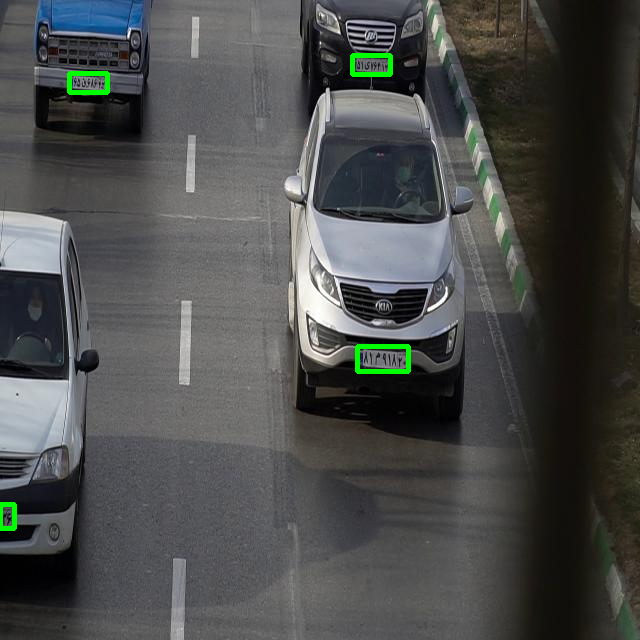

In [4]:
import cv2
import os
from google.colab import drive, files
from google.colab.patches import cv2_imshow
from ultralytics import YOLO

# ۱. متصل کردن گوگل درایو برای دسترسی به فایل‌های ذخیره‌شده
drive.mount("/content/drive")

# ۲. مسیر وزن مدل پلاک‌یاب روی گوگل درایو
detector_path = "/content/drive/MyDrive/Iranian_ALPR_Models/detector_best.pt"

# بررسی وجود فایل وزن در درایو
if os.path.exists(detector_path):
    detector = YOLO(detector_path)
    print("✅ مدل پلاک‌یاب با موفقیت از گوگل درایو بارگذاری شد.")

    # ۳. آپلود عکس و اجرای تست
    print("\n📸 یک عکس ماشین برای تست پلاک‌یاب آپلود کنید:")
    uploaded = files.upload()

    for img_name in uploaded.keys():
        img = cv2.imread(img_name)
        results = detector(img)[0]

        if len(results.boxes) == 0:
            print("❌ هیچ پلاکی پیدا نشد.")
        else:
            for i, box in enumerate(results.boxes.xyxy):
                x1, y1, x2, y2 = map(int, box[:4])

                # کات کردن و نمایش پلاک
                plate_crop = img[y1:y2, x1:x2]
                print(f"\n--- پلاک کات‌شده شماره {i+1} ---")
                cv2_imshow(plate_crop)

                # رسم باکس سبز دور پلاک روی عکس اصلی
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)

            print("\n--- تصویر کل خودرو ---")
            cv2_imshow(img)
else:
    print(
        f"❌ فایل وزن در مسیر زیر پیدا نشد:\n{detector_path}\nلطفاً از وجود فایل detector_best.pt در پوشه Iranian_ALPR_Models مطمئن شوید."
    )

In [5]:
import os
import shutil
import yaml
from ultralytics import YOLO

# ۱. ساخت پوشه و دانلود دیتاست دوم (OCR) از کگل
print("⏳ در حال دانلود و استخراج دیتاست کاراکترها...")
!mkdir -p /content/dataset_ocr
!kaggle datasets download -d ashkan0201/iran-license-plate-yolo
!unzip -q iran-license-plate-yolo.zip -d /content/dataset_ocr

if os.path.exists("iran-license-plate-yolo.zip"):
    os.remove("iran-license-plate-yolo.zip")

# ۲. تنظیم دقیق فایل data.yaml
ocr_yaml_path = "/content/dataset_ocr/data.yaml"

ocr_yaml_data = {
    "path": "/content/dataset_ocr",
    "train": "train/images",
    "val": "validation/images",
    "test": "test/images",
    "names": {
        0: "0",
        1: "1",
        2: "2",
        3: "3",
        4: "4",
        5: "5",
        6: "6",
        7: "7",
        8: "8",
        9: "9",
        10: "D",
        11: "S",
        12: "الف",
        13: "ب",
        14: "ت",
        15: "تشریفات",
        16: "ث",
        17: "ج",
        18: "د",
        19: "ز",
        20: "س",
        21: "ش",
        22: "ص",
        23: "ط",
        24: "ظ",
        25: "ع",
        26: "ف",
        27: "ق",
        28: "ل",
        29: "م",
        30: "ن",
        31: "ه",
        32: "ه‍",
        33: "و",
        34: "پ",
        35: "ژ",
        36: "ک",
        37: "گ",
        38: "ی",
    },
}

with open(ocr_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(ocr_yaml_data, f, allow_unicode=True)

print("✅ فایل data.yaml ایجاد شد.")

# ۳. شروع آموزش مدل دوم (OCR)
print("🚀 شروع آموزش مدل OCR روی کاراکترها...")
ocr_model = YOLO("yolov8n.pt")

results_ocr = ocr_model.train(
    data=ocr_yaml_path,
    epochs=25,
    imgsz=320,
    batch=32,
    project="stage2_ocr",
    name="char_reader",
)

print("\n✅ آموزش مدل OCR هم با موفقیت تمام شد!")

⏳ در حال دانلود و استخراج دیتاست کاراکترها...
Dataset URL: https://www.kaggle.com/datasets/ashkan0201/iran-license-plate-yolo
License(s): MIT
100% 849M/849M [00:43<00:00, 20.3MB/s]

✅ فایل data.yaml ایجاد شد.
🚀 شروع آموزش مدل OCR روی کاراکترها...
Ultralytics 8.4.129 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_ocr/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_

RuntimeError: Dataset '/content/dataset_ocr/data.yaml' error ❌ Dataset '/content/dataset_ocr/data.yaml' images not found, missing path '/content/dataset_ocr/validation/images'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [6]:
import os
import shutil
from google.colab import drive

# ۱. اتصال به گوگل درایو (اگر از قبل وصل نشده باشد)
drive.mount('/content/drive')

# ۲. ساخت پوشه مقصد در گوگل درایو
drive_save_path = "/content/drive/MyDrive/Iranian_ALPR_Models"
os.makedirs(drive_save_path, exist_ok=True)

# ۳. کپی کردن وزن‌های مدل اول (پلاک‌یاب)
detector_weight_source = "/content/runs/detect/stage1_detector/plate_finder-2/weights/best.pt"
detector_weight_target = os.path.join(drive_save_path, "detector_best.pt")

if os.path.exists(detector_weight_source):
    shutil.copy(detector_weight_source, detector_weight_target)
    print("✅ وزن‌های مدل اول (پلاک‌یاب) با موفقیت در گوگل درایو ذخیره شد:")
    print(detector_weight_target)
else:
    print("⚠️ مسیر پیش‌فرض پیدا نشد، در حال جستجوی تمامی فایل‌های best.pt مربوط به مرحله اول...")
    import glob
    found_files = glob.glob("/content/**/stage1_detector/**/best.pt", recursive=True)
    if found_files:
        shutil.copy(found_files[0], detector_weight_target)
        print("✅ فایل پیدا شد و در گوگل درایو ذخیره گردید:")
        print(detector_weight_target)
    else:
        print("❌ هیچ فایل وزنی برای مرحله اول یافت نشد.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⚠️ مسیر پیش‌فرض پیدا نشد، در حال جستجوی تمامی فایل‌های best.pt مربوط به مرحله اول...
❌ هیچ فایل وزنی برای مرحله اول یافت نشد.


In [7]:
import glob
import os
import yaml
from google.colab import drive
from ultralytics import YOLO

# ۱. متصل کردن گوگل درایو
drive.mount("/content/drive")

# ساخت پوشه مخصوص ذخیره مدل‌ها در درایو
drive_save_path = "/content/drive/MyDrive/Iranian_ALPR_Models"
os.makedirs(drive_save_path, exist_ok=True)

# ---------------------------------------------------------
# ۲. بررسی و اصلاح مسیرهای data.yaml دیتاست OCR
# ---------------------------------------------------------
base_ocr_path = "/content/dataset_ocr"
images_dirs = glob.glob(f"{base_ocr_path}/**/images", recursive=True)

train_rel_path = "train/images"
val_rel_path = "valid/images"

for path in images_dirs:
    rel = os.path.relpath(path, base_ocr_path)
    if "train" in rel:
        train_rel_path = rel
    elif "val" in rel or "valid" in rel:
        val_rel_path = rel

ocr_yaml_path = f"{base_ocr_path}/data.yaml"

# اگر فایل data.yaml از قبل وجود دارد، کلاس‌های آن را حفظ کن
if os.path.exists(ocr_yaml_path):
    with open(ocr_yaml_path, "r", encoding="utf-8") as f:
        existing_yaml = yaml.safe_load(f)
    names_dict = existing_yaml.get("names", {})
else:
    names_dict = {
        0: "0",
        1: "1",
        2: "2",
        3: "3",
        4: "4",
        5: "5",
        6: "6",
        7: "7",
        8: "8",
        9: "9",
        10: "D",
        11: "S",
        12: "الف",
        13: "ب",
        14: "ت",
        15: "تشریفات",
        16: "ث",
        17: "ج",
        18: "د",
        19: "ز",
        20: "س",
        21: "ش",
        22: "ص",
        23: "ط",
        24: "ظ",
        25: "ع",
        26: "ف",
        27: "ق",
        28: "ل",
        29: "م",
        30: "ن",
        31: "ه",
        32: "ه‍",
        33: "و",
        34: "پ",
        35: "ژ",
        36: "ک",
        37: "گ",
        38: "ی",
    }

ocr_yaml_data = {
    "path": base_ocr_path,
    "train": train_rel_path,
    "val": val_rel_path,
    "names": names_dict,
}

with open(ocr_yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(ocr_yaml_data, f, allow_unicode=True)

print("✅ فایل data.yaml آماده شد.")

# ---------------------------------------------------------
# ۳. شروع آموزش و ذخیره مستقیم فایل‌های وزن در گوگل درایو
# ---------------------------------------------------------
print("🚀 شروع آموزش مدل OCR کاراکترها (ذخیره‌سازی مستقیم در درایو)...")
ocr_model = YOLO("yolov8n.pt")

results_ocr = ocr_model.train(
    data=ocr_yaml_path,
    epochs=25,
    imgsz=320,
    batch=32,
    project=drive_save_path,  # خروجی مستقیماً در Google Drive ذخیره می‌شود
    name="stage2_ocr_char_reader",
)

print("\n✅ آموزش مدل دوم با موفقیت تمام شد!")
print(
    f"📁 وزن‌های مدل در مسیر زیر در گوگل درایو ذخیره شدند:\n{drive_save_path}/stage2_ocr_char_reader/weights/best.pt"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ فایل data.yaml آماده شد.
🚀 شروع آموزش مدل OCR کاراکترها (ذخیره‌سازی مستقیم در درایو)...
Ultralytics 8.4.129 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_ocr/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320,

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ هر دو مدل (Detector + OCR) با موفقیت بارگذاری شدند!

📸 تصویر یک خودرو را آپلود کنید:


Saving 2.jpg to 2.jpg

0: 640x640 1 license_plate, 7.2ms
Speed: 2.0ms preprocess, 7.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 224x320 1 1, 1 2, 1 3, 1 4, 2 6s, 1 9, 1 ق, 5.6ms
Speed: 1.9ms preprocess, 5.6ms inference, 1.2ms postprocess per image at shape (1, 3, 224, 320)

--- پلاک کات‌شده شماره 1 ---


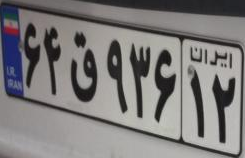

🔑 شماره پلاک خوانده شده:  6 4 ق 9 3 6 1 2

--- تصویر کل خودرو ---


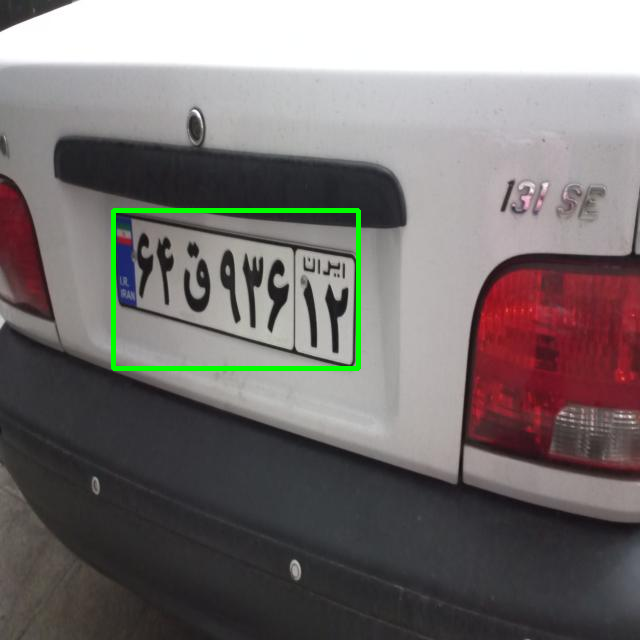

In [10]:
import cv2
import os
from google.colab import drive, files
from google.colab.patches import cv2_imshow
from ultralytics import YOLO

# ۱. متصل کردن درایو
drive.mount("/content/drive")

# ۲. مسیر وزن‌ها از گوگل درایو
detector_path = "/content/drive/MyDrive/Iranian_ALPR_Models/detector_best.pt"
ocr_path = "/content/drive/MyDrive/Iranian_ALPR_Models/stage2_ocr_char_reader-2/weights/best.pt"

if not os.path.exists(ocr_path):
    # اگر پسوند شماره نداشت این مسیر را بگردد
    ocr_path = "/content/drive/MyDrive/Iranian_ALPR_Models/stage2_ocr_char_reader/weights/best.pt"

# بارگذاری هر دو مدل
detector_model = YOLO(detector_path)
ocr_model = YOLO(ocr_path)
print("✅ هر دو مدل (Detector + OCR) با موفقیت بارگذاری شدند!")

# ۳. اپلود تصویر تست
print("\n📸 تصویر یک خودرو را آپلود کنید:")
uploaded = files.upload()

for img_name in uploaded.keys():
    img = cv2.imread(img_name)

    # مرحله اول: پیدا کردن پلاک
    det_results = detector_model(img)[0]

    if len(det_results.boxes) == 0:
        print("❌ هیچ پلاکی روی این خودرو یافت نشد.")
    else:
        for i, box in enumerate(det_results.boxes.xyxy):
            x1, y1, x2, y2 = map(int, box[:4])

            # کات کردن دقیق تصویر پلاک
            plate_crop = img[y1:y2, x1:x2]

            # مرحله دوم: تشخیص کاراکترها روی پلاک کات‌شده
            ocr_results = ocr_model(plate_crop)[0]

            detected_chars = []
            for char_box in ocr_results.boxes:
                cx1, cy1, cx2, cy2 = map(int, char_box.xyxy[0])
                cls_id = int(char_box.cls[0])
                char_label = ocr_model.names[cls_id]

                # ذخیره کاراکتر و مختصات X برای مرتب‌سازی از چپ به راست
                detected_chars.append((cx1, char_label))

            # مرتب‌سازی حروف بر اساس موقعیت افقی (X) از چپ به راست
            detected_chars.sort(key=lambda x: x[0])
            plate_text = " ".join([c[1] for c in detected_chars])

            # نمایش نتایج
            print(f"\n--- پلاک کات‌شده شماره {i+1} ---")
            cv2_imshow(plate_crop)
            print(f"🔑 شماره پلاک خوانده شده:  {plate_text}")

            # کشیدن کادر سبز روی عکس اصلی
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)

        print("\n--- تصویر کل خودرو ---")
        cv2_imshow(img)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ مدل‌ها با موفقیت بارگذاری شدند!


Saving 4.jpg to 4 (2).jpg

0: 640x640 4 license_plates, 7.1ms
Speed: 2.9ms preprocess, 7.1ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)

0: 160x320 1 0, 2 1s, 1 2, 2 8s, 1 9, 1 م, 5.3ms
Speed: 1.0ms preprocess, 5.3ms inference, 1.1ms postprocess per image at shape (1, 3, 160, 320)

--- پلاک کات‌شده شماره 1 ---


📌 اجزای پلاک:
  [۲ رقم چپ]: 81
  [حرف وسط]:  م
  [۳ رقم راست]: 918
  [کد ایران]:  20

🔑 خروجی استاندارد سیستم: 918 - م - 81 | Iran: 20

0: 160x320 2 1s, 1 2, 1 4, 1 5, 1 6, 1 7, 1 گ, 6.5ms
Speed: 1.3ms preprocess, 6.5ms inference, 1.1ms postprocess per image at shape (1, 3, 160, 320)

--- پلاک کات‌شده شماره 2 ---


📌 اجزای پلاک:
  [۲ رقم چپ]: 51
  [حرف وسط]:  گ
  [۳ رقم راست]: 764
  [کد ایران]:  12

🔑 خروجی استاندارد سیستم: 764 - گ - 51 | Iran: 12

0: 160x320 1 2, 1 4, 1 5, 3 6s, 1 8, 1 ق, 6.7ms
Speed: 0.7ms preprocess, 6.7ms inference, 1.1ms postprocess per image at shape (1, 3, 160, 320)

--- پلاک کات‌شده شماره 3 ---


📌 اجزای پلاک:
  [۲ رقم چپ]: 65
  [حرف وسط]:  ق
  [۳ رقم راست]: 6864
  [کد ایران]:  2

🔑 خروجی استاندارد سیستم: 6864 - ق - 65 | Iran: 2

0: 320x192 (no detections), 7.5ms
Speed: 0.8ms preprocess, 7.5ms inference, 0.5ms postprocess per image at shape (1, 3, 320, 192)

--- پلاک کات‌شده شماره 4 ---


📌 اجزای پلاک:
  [۲ رقم چپ]: 
  [حرف وسط]:  
  [۳ رقم راست]: 
  [کد ایران]:  

🔑 خروجی استاندارد سیستم:  -  -  | Iran: 

--- تصویر کل خودرو ---


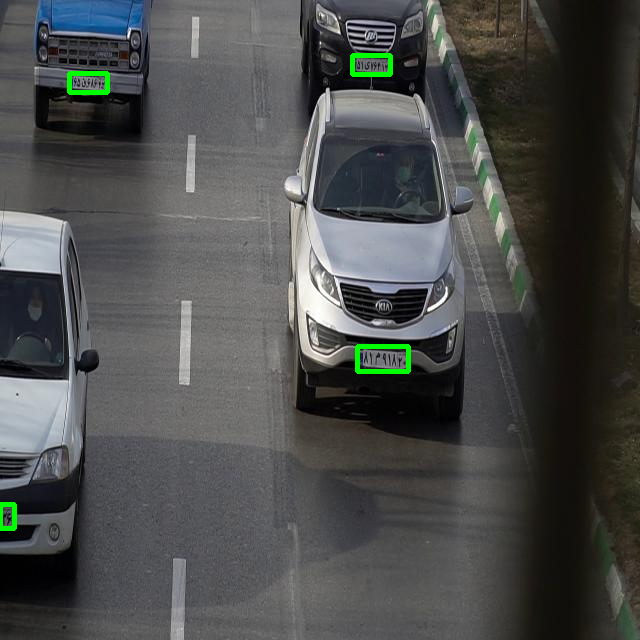

In [20]:
import cv2
import os
from google.colab import drive, files
from google.colab.patches import cv2_imshow
from ultralytics import YOLO

# ۱. اتصال به درایو و بارگذاری مدل‌ها
drive.mount("/content/drive")

detector_path = "/content/drive/MyDrive/Iranian_ALPR_Models/detector_best.pt"
ocr_base_dir = "/content/drive/MyDrive/Iranian_ALPR_Models"
ocr_folders = [
    f
    for f in os.listdir(ocr_base_dir)
    if f.startswith("stage2_ocr_char_reader")
]
ocr_folders.sort()
latest_ocr_folder = ocr_folders[-1] if ocr_folders else "stage2_ocr_char_reader"
ocr_path = os.path.join(ocr_base_dir, latest_ocr_folder, "weights", "best.pt")

detector_model = YOLO(detector_path)
ocr_model = YOLO(ocr_path)
print("✅ مدل‌ها با موفقیت بارگذاری شدند!")

PERSIAN_LETTERS = [
    "الف",
    "ب",
    "ت",
    "ث",
    "ج",
    "د",
    "ز",
    "س",
    "ش",
    "ص",
    "ط",
    "ظ",
    "ع",
    "ف",
    "ق",
    "ل",
    "م",
    "ن",
    "ه",
    "ه‍",
    "و",
    "پ",
    "ژ",
    "ک",
    "گ",
    "ی",
    "D",
    "S",
    "تشریفات",
]

# ۲. اجرای خط لوله هوشمند پلاک‌خوان
uploaded = files.upload()

for img_name in uploaded.keys():
    img = cv2.imread(img_name)
    det_results = detector_model(img)[0]

    if len(det_results.boxes) == 0:
        print("❌ هیچ پلاکی پیدا نشد.")
    else:
        for i, box in enumerate(det_results.boxes.xyxy):
            x1, y1, x2, y2 = map(int, box[:4])
            plate_crop = img[y1:y2, x1:x2]
            plate_width = plate_crop.shape[1]

            ocr_results = ocr_model(plate_crop)[0]

            detected_chars = []
            for char_box in ocr_results.boxes:
                cx1, cy1, cx2, cy2 = map(int, char_box.xyxy[0])
                cls_id = int(char_box.cls[0])
                char_label = ocr_model.names[cls_id]

                center_x = (cx1 + cx2) / 2
                detected_chars.append((center_x, char_label))

            # مرتب‌سازی افقی (از چپ به راست)
            detected_chars.sort(key=lambda item: item[0])

            # تفکیک پلاک اصلی از کد ایران (کادر ۲۰٪ سمت راست)
            main_chars = []
            iran_code_chars = []

            for center_x, label in detected_chars:
                if center_x < (plate_width * 0.78):
                    main_chars.append(label)
                else:
                    iran_code_chars.append(label)

            # استخراج اجزای پلاک
            left_two_digits = ""
            letter = ""
            right_three_digits = ""

            letter_idx = -1
            for idx, label in enumerate(main_chars):
                if label in PERSIAN_LETTERS:
                    letter_idx = idx
                    letter = label
                    break

            if letter_idx != -1:
                left_two_digits = "".join(main_chars[:letter_idx])
                right_three_digits = "".join(main_chars[letter_idx + 1 :])
            else:
                raw_main = "".join(main_chars)
                left_two_digits = raw_main[:2]
                right_three_digits = raw_main[2:]

            iran_code = "".join(iran_code_chars)

            print(f"\n--- پلاک کات‌شده شماره {i+1} ---")
            cv2_imshow(plate_crop)

            # ۱. نمایش تفکیک‌شده اجزا
            print("📌 اجزای پلاک:")
            print(f"  [۲ رقم چپ]: {left_two_digits}")
            print(f"  [حرف وسط]:  {letter}")
            print(f"  [۳ رقم راست]: {right_three_digits}")
            print(f"  [کد ایران]:  {iran_code}")

            # ۲. اصلاح جایگاه ۲ رقم و ۳ رقم در خروجی متنی یک‌خطی
            formatted_clean = f"{right_three_digits} - {letter} - {left_two_digits} | Iran: {iran_code}"
            print(f"\n🔑 خروجی استاندارد سیستم: {formatted_clean}")

            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)

        print("\n--- تصویر کل خودرو ---")
        cv2_imshow(img)

In [16]:
!pip install gradio -q

In [21]:
# ۱. نصب کتابخانه‌های مورد نیاز
!pip install -q ultralytics gradio

import cv2
import gradio as gr
import numpy as np
import os
from google.colab import drive
from ultralytics import YOLO

# ۲. اتصال به گوگل درایو
drive.mount("/content/drive")

# ۳. تنظیم مسیر وزن‌ها از گوگل درایو
BASE_DRIVE_DIR = "/content/drive/MyDrive/Iranian_ALPR_Models"

detector_path = os.path.join(BASE_DRIVE_DIR, "detector_best.pt")

ocr_folders = [
    f for f in os.listdir(BASE_DRIVE_DIR) if f.startswith("stage2_ocr_char_reader")
]
ocr_folders.sort()
latest_ocr_folder = ocr_folders[-1] if ocr_folders else "stage2_ocr_char_reader"
ocr_path = os.path.join(BASE_DRIVE_DIR, latest_ocr_folder, "weights", "best.pt")

if not os.path.exists(detector_path):
    raise FileNotFoundError(f"❌ مدل پلاک‌یاب در مسیر {detector_path} یافت نشد!")
if not os.path.exists(ocr_path):
    raise FileNotFoundError(f"❌ مدل OCR در مسیر {ocr_path} یافت نشد!")

detector_model = YOLO(detector_path)
ocr_model = YOLO(ocr_path)
print("✅ هر دو مدل با موفقیت بارگذاری شدند!")

PERSIAN_LETTERS = [
    "الف", "ب", "ت", "ث", "ج", "د", "ز", "س", "ش", "ص", "ط", "ظ", "ع",
    "ف", "ق", "ل", "م", "ن", "ه", "ه‍", "و", "پ", "ژ", "ک", "گ", "ی", "D", "S", "تشریفات"
]

# ۴. تابع پردازش چند پلاک هم‌زمان
def process_alpr(input_image):
    if input_image is None:
        return None, [], "تصویری انتخاب نشده است."

    img = cv2.cvtColor(input_image, cv2.COLOR_RGB2BGR)
    det_results = detector_model(img)[0]

    if len(det_results.boxes) == 0:
        return input_image, [], "❌ هیچ پلاکی روی این تصویر یافت نشد."

    cropped_plates_gallery = []
    results_text_list = []

    # پردازش تک‌تک پلاک‌های کشف شده (بدون break)
    for i, box in enumerate(det_results.boxes.xyxy):
        x1, y1, x2, y2 = map(int, box[:4])
        plate_crop = img[y1:y2, x1:x2]
        plate_width = plate_crop.shape[1]

        # کادر سبز روی عکس اصلی
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 4)

        # تبدیل برای نمایش در گالری UI
        plate_crop_rgb = cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB)
        cropped_plates_gallery.append(plate_crop_rgb)

        # مرحله OCR
        ocr_results = ocr_model(plate_crop)[0]
        detected_chars = []

        for char_box in ocr_results.boxes:
            cx1, cy1, cx2, cy2 = map(int, char_box.xyxy[0])
            cls_id = int(char_box.cls[0])
            char_label = ocr_model.names[cls_id]
            center_x = (cx1 + cx2) / 2
            detected_chars.append((center_x, char_label))

        detected_chars.sort(key=lambda item: item[0])

        main_chars = []
        iran_code_chars = []

        for center_x, label in detected_chars:
            if center_x < (plate_width * 0.78):
                main_chars.append(label)
            else:
                iran_code_chars.append(label)

        left_two_digits = ""
        letter = ""
        right_three_digits = ""

        letter_idx = -1
        for idx, label in enumerate(main_chars):
            if label in PERSIAN_LETTERS:
                letter_idx = idx
                letter = label
                break

        if letter_idx != -1:
            left_two_digits = "".join(main_chars[:letter_idx])
            right_three_digits = "".join(main_chars[letter_idx + 1:])
        else:
            raw_main = "".join(main_chars)
            left_two_digits = raw_main[:2]
            right_three_digits = raw_main[2:]

        iran_code = "".join(iran_code_chars)

        formatted_clean = f"{right_three_digits} - {letter} - {left_two_digits} | Iran: {iran_code}"

        plate_info = (
            f"🚘 **پلاک شماره {i+1}:**\n"
            f"• اجزا: [{left_two_digits}] [{letter}] [{right_three_digits}] (ایران {iran_code})\n"
            f"• خروجی: {formatted_clean}\n"
            f"----------------------------------------"
        )
        results_text_list.append(plate_info)

    output_img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    full_text_output = "\n".join(results_text_list)

    return output_img_rgb, cropped_plates_gallery, full_text_output

# ۵. راه اندازی رابط کاربری
with gr.Blocks(title="سیستم پلاک‌خوان چندتایی (ANPR)") as demo:
    gr.Markdown("# 🚗 سامانه هوشمند پلاک‌خوان ایرانی (پشتیبانی از چند خودرو)")

    with gr.Row():
        with gr.Column():
            input_img = gr.Image(type="numpy", label="تصویر ورودی")
            btn = gr.Button("پردازش تمام پلاک‌ها", variant="primary")

        with gr.Column():
            output_full_img = gr.Image(label="تصویر اصلی با کادر پلاک‌ها")
            output_gallery = gr.Gallery(label="پلاک‌های کات‌شده", columns=2, height=200)
            output_text = gr.Textbox(label="نتایج استخراج‌شده", interactive=False, lines=10)

    btn.click(
        fn=process_alpr,
        inputs=[input_img],
        outputs=[output_full_img, output_gallery, output_text],
    )

demo.launch(share=True, debug=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ هر دو مدل با موفقیت بارگذاری شدند!
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3f3a14a769b17169c8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



0: 640x640 4 license_plates, 7.2ms
Speed: 3.6ms preprocess, 7.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 160x320 1 0, 2 1s, 1 2, 2 8s, 1 9, 1 م, 6.9ms
Speed: 1.3ms preprocess, 6.9ms inference, 1.4ms postprocess per image at shape (1, 3, 160, 320)

0: 160x320 2 1s, 1 2, 1 4, 1 5, 1 6, 1 7, 1 گ, 6.7ms
Speed: 0.8ms preprocess, 6.7ms inference, 1.3ms postprocess per image at shape (1, 3, 160, 320)

0: 160x320 1 2, 1 4, 1 5, 3 6s, 1 8, 1 ق, 7.0ms
Speed: 0.9ms preprocess, 7.0ms inference, 1.3ms postprocess per image at shape (1, 3, 160, 320)

0: 320x192 (no detections), 45.4ms
Speed: 1.5ms preprocess, 45.4ms inference, 0.6ms postprocess per image at shape (1, 3, 320, 192)

0: 640x640 2 license_plates, 40.8ms
Speed: 3.7ms preprocess, 40.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

0: 160x320 2 4s, 1 5, 1 7, 1 8, 2 9s, 1 د, 42.8ms
Speed: 1.2ms preprocess, 42.8ms inference, 1.4ms postprocess per image at shape (1, 3, 160, 320)

0: 160x320 